<h1>Speech recognition with the Whisper model</h1>

In [8]:
#BEFORE RUNNING THIS ON YOUR OWN DEVICE PREREQUISITET INSTALLS ARE:

%pip install torch
%pip install transformers
%pip install librosa
%pip install ipywidgets
%pip install PySoundFile
%pip install sentencepiece
%pip install sacremoses

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


<h2>1. Business understanding</h2>

   - Määritellään ratkaistava liiketoimintaongelma (business problem).
   - Tavoitteena on selvittää analyysin päämäärä (goal), vaatimukset (requirements), rajoitteet (constraints) ja odotettu lopputulos (expected outcome).

Tavoite

Käytä esikoulutettua Whisper-mallia suomenkielisen puheen tunnistamiseen. Tutki mallin toimintaa, rajoituksia ja eri kokojen välisiä eroja — ja ymmärrä, miten äänidata muunnetaan transformer-mallille sopivaan muotoon.

This assignment anwers questions like:

- Mitä x- ja y-akselit kuvaavat spektrogrammissa?
- Mitä väri (desibelit) kertoo?
- Miksi tämä esitysmuoto sopii paremmin neuroverkolle kuin raaka äänisignaali?

Tehtävät:
1. Tallenna tai hanki suomenkielisiä ääninäytteitä (alle 30 sekuntia per näyte)
2. Tunnista puhe vähintään kahdella erikokoisella Whisper-mallilla (esim. tiny, base, small, large)
3. Kokeile erilaisia äänisyötteitä: selkeä puhe, taustahäly, eri puhujat, murre

Kokeile:

1. Miten mallin koko vaikuttaa tunnistustarkkuuteen ja nopeuteen?
2. Missä tilanteissa pienempi malli riittää, missä tarvitaan suurempi?
3. Mikä on mallin käyttäytyminen epäselvän tai meluisan puheen kanssa?
4. Kokeile myös englanninkielistä puhetta — toimiiko malli yhtä hyvin?

Raportoi:

1. Käytetyt ääninäytteet ja niiden kuvaukset
2. Vertailu eri mallien välillä (tarkkuus, nopeus, virheet)
3. Analyysi tilanteista, joissa malli onnistuu ja epäonnistuu
4. Miksi Whisper käyttää mel-spektrogrammia? Miten tämä liittyy Osan 1 transformer-malliin?

Palauta:

1. Puheentunnistuksen suorituskyvyn arviointi eri malleilla
2. Mel-spektrogrammin selitys omin sanoin
3. Pohdinta transformer-mallien vahvuuksista ja rajoituksista

<h2>2. Data understanding</h2>

   - Kerätään ja tutkitaan saatavilla olevaa dataa.
   - Tässä kartoitetaan datan ominaisuudet, kuten muuttujatyypit ja arvojakaumat, sekä mahdolliset laatuongelmat (quality issues), kuten puuttuvat arvot (missing values), poikkeamat (outliers) ja järjettömät arvot (nonsensical values).

In [12]:
import torch
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from transformers import WhisperProcessor, WhisperForConditionalGeneration

# Set the audio filename - update this to your actual filename
af_01 = "audio/01_plain_finnish.wav"
af_02 = ""
af_03 = ""
af_04 = ""

In [13]:
# Load audio file
y, sr = librosa.load(af_01, sr=16000)

# Display audio for playback
print("Play the audio:")
display(Audio(y, rate=sr))

# Print audio statistics
duration = librosa.get_duration(y=y, sr=sr)

print(f"\nAudio Statistics:")
print(f"Duration: {duration:.2f} seconds")
print(f"Sample rate: {sr} Hz")
print(f"Audio shape: {y.shape}")
print(f"Data type: {y.dtype}")

Play the audio:



Audio Statistics:
Duration: 6.40 seconds
Sample rate: 16000 Hz
Audio shape: (102381,)
Data type: float32


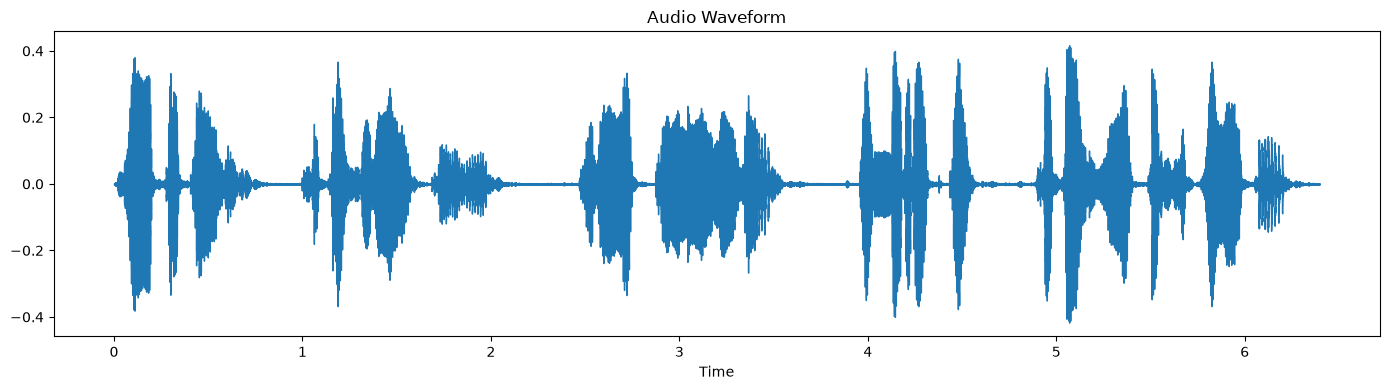

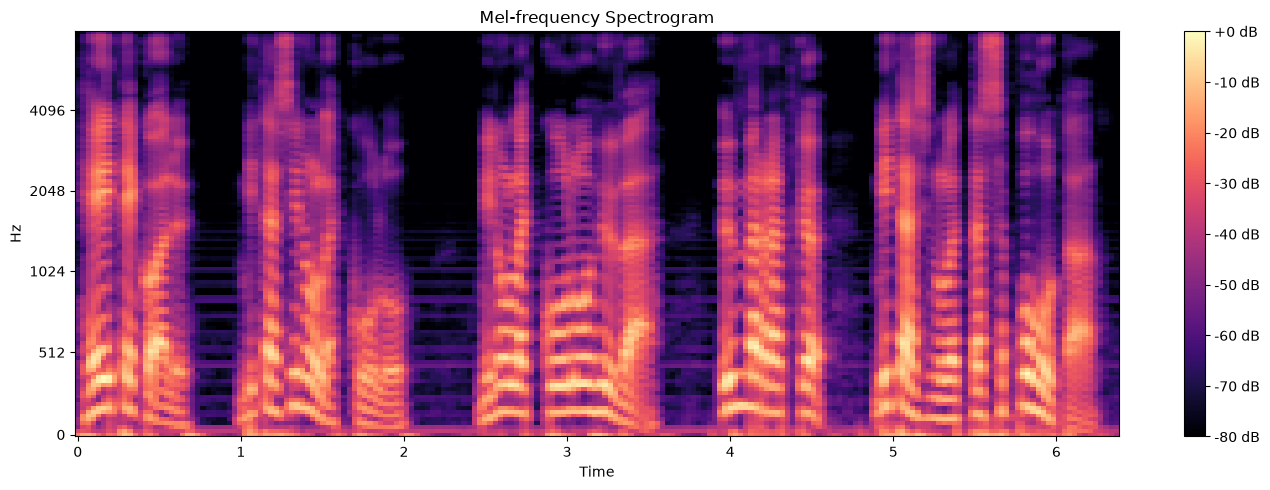

In [11]:
# Plot waveform
plt.figure(figsize=(14, 4))
librosa.display.waveshow(y, sr=sr)
plt.title('Audio Waveform')
plt.tight_layout()
plt.show()

# Create mel spectrogram
plt.figure(figsize=(14, 5))
S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
S_dB = librosa.power_to_db(S, ref=np.max)
librosa.display.specshow(S_dB, y_axis='mel', x_axis='time', sr=sr)
plt.colorbar(format='%+2.0f dB')
plt.title('Mel-frequency Spectrogram')
plt.tight_layout()
plt.show()

<h2>3. Data preparation</h2>

   - Data siivotaan, muunnetaan ja valitaan olennaiset piirteet (features).
   - Kaikki nämä vaiheet tulee dokumentoida niin tarkasti, että ne ovat myöhemmin täysin toistettavissa.

<h2>4. Modeling</h2>

 - Valitaan koneoppimismenetelmä, opetetaan malli ja validoidaan se (validation).
 - Dokumentointiin on sisällytettävä tarkasti valittu menetelmä, käytetyt parametrit sekä mitattu mallin suorituskyky.
 - Millä perusteella tehty valinnat
 - Taulukko on hyvä viestimiseen
 - Ei tarvitse olla yksityiskohtainen, mutta selitetään miksi on päädytty lopputulokseen.

<h2>5. Evaluation</h2>

 - Arvioidaan mallin todellinen onnistuminen.
 - Selvitetään, kuinka hyvin malli vastaa sille alun perin asetettuihin liiketoimintavaatimuksiin (business requirements).<br>
 - Ei katsota mallin suorituskykyä (tämä tehdään kappaleessa 4), vaan palataan takaisin kappaleeseen 1. ja millä tavalla saavutetut tulokset vertautuu alkuperäisiin tavoitteisiin.

<h2>6. Deployment</h2>

- Malli viedään käytäntöön (deployment).
- Tähän sisältyy tulosten viestiminen ja suositusten luominen siitä, miten mallia tulisi hyödyntää käytännössä tai mitä jatkotoimenpiteitä tulisi tehdä.